# Day 19 — Feature Engineering & ML Pipelines
**Institute deliverable:** Complete preprocessing pipeline: Raw Data → Cleaning → Feature Engineering → Encoding → Scaling → Train/Test → Model.  
**Data provenance:** The original numeric features and `Churn` label come from the Day 17 synthetic customer-churn dataset. For Day 19 practice, categorical features and missing values were **synthetically added** with a fixed random seed. They are not real customer attributes.  
**Leakage prevention:** Fit imputation, encoding, scaling, feature selection and model only on training folds via a scikit-learn Pipeline. The holdout test set is used once for final evaluation.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.dummy import DummyClassifier
from joblib import dump
RANDOM_STATE=42
OUTPUT=Path('outputs'); OUTPUT.mkdir(exist_ok=True)
print('Libraries loaded; random_state =',RANDOM_STATE)

Libraries loaded; random_state = 42


## 2. Raw data, data understanding and missing values

In [2]:
df=pd.read_csv('customer_churn_day19_enriched.csv')
print('Dataset shape:',df.shape)
print('Duplicate customer IDs:',df.Customer_ID.duplicated().sum())
print('Churn counts:')
print(df.Churn.value_counts().to_string())
print('Missing values:')
print(df.isna().sum().to_string())
display(df.head())

Dataset shape: (500, 10)
Duplicate customer IDs: 0
Churn counts:
Churn
1    276
0    224
Missing values:
Customer_ID               0
Tenure_Months             0
Monthly_Charges_INR      22
Support_Calls_90_Days     0
Annual_Contract           0
Satisfaction_Score       18
Churn                     0
Payment_Method           16
Internet_Service         14
City_Tier                 0


,Customer_ID,Tenure_Months,Monthly_Charges_INR,Support_Calls_90_Days,Annual_Contract,Satisfaction_Score,Churn,Payment_Method,Internet_Service,City_Tier
0,C0001,36,860.06,2,0,1.0,1,UPI,Fiber,Metro
1,C0002,48,2309.90,0,0,1.0,1,UPI,Fiber,Tier 3
2,C0003,42,2386.31,3,1,2.0,1,UPI,Fiber,Tier 2
3,C0004,62,1316.80,4,0,2.0,1,Card,Mobile,Metro
4,C0005,7,907.97,3,0,2.0,0,UPI,DSL,Tier 3


## 3. Cleaning and feature creation
We remove the identifier from predictors and add two domain-inspired features: `Charges_Per_Tenure` and `Support_Calls_Per_Month`. These are derived from input features only (never from `Churn`). Division is protected against zero tenure. Missing input values propagate to the derived feature and are imputed later **inside the pipeline**.

In [3]:
def create_features(frame):
    X=frame.drop(columns=['Customer_ID','Churn']).copy()
    tenure=X['Tenure_Months'].clip(lower=1)
    X['Charges_Per_Tenure']=X['Monthly_Charges_INR']/tenure
    X['Support_Calls_Per_Month']=X['Support_Calls_90_Days']/3.0
    return X
X=create_features(df)
y=df['Churn'].astype(int)
print('Predictor columns:',X.columns.tolist())
print('New feature examples:')
display(X[['Charges_Per_Tenure','Support_Calls_Per_Month']].head())

Predictor columns: ['Tenure_Months', 'Monthly_Charges_INR', 'Support_Calls_90_Days', 'Annual_Contract', 'Satisfaction_Score', 'Payment_Method', 'Internet_Service', 'City_Tier', 'Charges_Per_Tenure', 'Support_Calls_Per_Month']
New feature examples:


,Charges_Per_Tenure,Support_Calls_Per_Month
0,23.890556,0.666667
1,48.122917,0.000000
2,56.816905,1.000000
3,21.238710,1.333333
4,129.710000,1.000000


## 4. Train/test split (stratified, before fitting transformations)

In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=RANDOM_STATE,stratify=y)
print('Train:',X_train.shape,'Test:',X_test.shape)
print('Train churn rate:',round(y_train.mean(),3),'Test churn rate:',round(y_test.mean(),3))

Train: (400, 10) Test: (100, 10)
Train churn rate: 0.552 Test churn rate: 0.55


## 5. Imputation, one-hot encoding, and scaling
- Numerical columns: median imputation → StandardScaler (zero mean/unit variance, fitted on training folds).
- Categorical columns: most-frequent imputation → OneHotEncoder(handle_unknown="ignore").
- `MinMaxScaler` is demonstrated separately; **do not fit it on the full dataset before splitting**.
- Binary `Annual_Contract` remains numeric; this is a valid representation for a 0/1 indicator.

In [5]:
num_cols=X.select_dtypes(include='number').columns.tolist()
cat_cols=X.select_dtypes(exclude='number').columns.tolist()
num_pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
cat_pipe=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
preprocess=ColumnTransformer([('numeric',num_pipe,num_cols),('categorical',cat_pipe,cat_cols)],remainder='drop')
print('Numeric:',num_cols)
print('Categorical:',cat_cols)
# Illustrative MinMaxScaler only, fitted on training subset
minmax_demo=Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',MinMaxScaler())])
mm=minmax_demo.fit_transform(X_train[num_cols]);print('MinMaxScaler sample:',np.round(mm[:2,:3],3))

Numeric: ['Tenure_Months', 'Monthly_Charges_INR', 'Support_Calls_90_Days', 'Annual_Contract', 'Satisfaction_Score', 'Charges_Per_Tenure', 'Support_Calls_Per_Month']
Categorical: ['Payment_Method', 'Internet_Service', 'City_Tier']
MinMaxScaler sample: [[0.648 0.836 0.   ]
 [0.423 0.257 0.2  ]]


## 6. Feature selection and complete ML pipeline
`SelectKBest(f_classif)` runs **after preprocessing and inside each CV fold**. Grid search chooses `k` and logistic-regression regularization `C`. One-hot encoded features are selected as individual columns. No test-set information is used during tuning.

In [6]:
pipeline=Pipeline([('preprocess',preprocess),('select',SelectKBest(score_func=f_classif,k=8)),('model',LogisticRegression(max_iter=2000,random_state=RANDOM_STATE))])
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
params={'select__k':[6,8,'all'],'model__C':[0.1,1.0,10.0]}
search=GridSearchCV(pipeline,params,scoring='roc_auc',cv=cv,n_jobs=1,refit=True,return_train_score=False)
search.fit(X_train,y_train)
print('Best CV ROC-AUC:',round(search.best_score_,4))
print('Best parameters:',search.best_params_)

Best CV ROC-AUC: 0.8261
Best parameters: {'model__C': 0.1, 'select__k': 6}


## 7. Cross-validation comparison against a baseline

In [7]:
baseline=DummyClassifier(strategy='prior')
# Baseline accepts raw X without preprocessing, and predicts training-fold prevalence
scoring={'accuracy':'accuracy','f1':'f1','roc_auc':'roc_auc'}
base_cv=cross_validate(baseline,X_train,y_train,cv=cv,scoring=scoring)
# Search.best_score_ is from CV; separate CV here estimates the tuned pipeline on training folds (illustrative, not nested CV)
tuned_cv=cross_validate(search.best_estimator_,X_train,y_train,cv=cv,scoring=scoring)
cv_results=pd.DataFrame({'Metric':['Accuracy','F1','ROC-AUC'],'Dummy baseline':[base_cv['test_accuracy'].mean(),base_cv['test_f1'].mean(),base_cv['test_roc_auc'].mean()],'Tuned pipeline':[tuned_cv['test_accuracy'].mean(),tuned_cv['test_f1'].mean(),tuned_cv['test_roc_auc'].mean()]})
display(cv_results.round(4));cv_results.to_csv(OUTPUT/'cross_validation_comparison.csv',index=False)
print('Note: tuned CV after hyperparameter search is descriptive, not an unbiased nested-CV estimate.')

,Metric,Dummy baseline,Tuned pipeline
0,Accuracy,0.5525,0.7650
1,F1,0.7117,0.7876
2,ROC-AUC,0.5000,0.8261


Note: tuned CV after hyperparameter search is descriptive, not an unbiased nested-CV estimate.


## 8. Final evaluation on untouched test set

,Metric,Test score
0,Accuracy,0.6400
1,Precision,0.6667
2,Recall,0.6909
3,F1,0.6786
4,ROC-AUC,0.6921


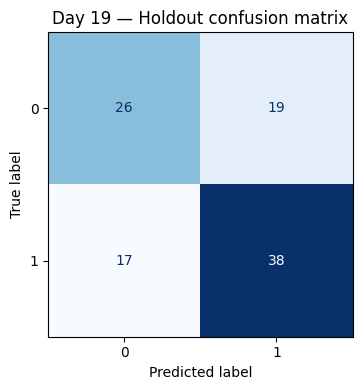

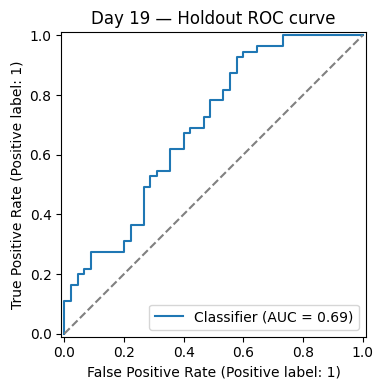

In [8]:
best=search.best_estimator_
pred=best.predict(X_test);proba=best.predict_proba(X_test)[:,1]
metrics={'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),'F1':f1_score(y_test,pred,zero_division=0),'ROC-AUC':roc_auc_score(y_test,proba)}
result=pd.DataFrame({'Metric':list(metrics),'Test score':list(metrics.values())})
display(result.round(4));result.to_csv(OUTPUT/'test_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(6,4));ConfusionMatrixDisplay.from_predictions(y_test,pred,ax=ax,cmap='Blues',colorbar=False);ax.set_title('Day 19 — Holdout confusion matrix');fig.tight_layout();fig.savefig(OUTPUT/'confusion_matrix.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(6,4));RocCurveDisplay.from_predictions(y_test,proba,ax=ax);ax.plot([0,1],[0,1],'--',color='gray');ax.set_title('Day 19 — Holdout ROC curve');fig.tight_layout();fig.savefig(OUTPUT/'roc_curve.png',dpi=150);plt.show()

## 9. Selected features and business interpretation

,Feature,Logistic coefficient
4,numeric__Satisfaction_Score,-0.679412
3,numeric__Annual_Contract,-0.630406
0,numeric__Tenure_Months,-0.434046
2,numeric__Support_Calls_90_Days,0.323510
5,numeric__Support_Calls_Per_Month,0.323510
1,numeric__Monthly_Charges_INR,0.678362


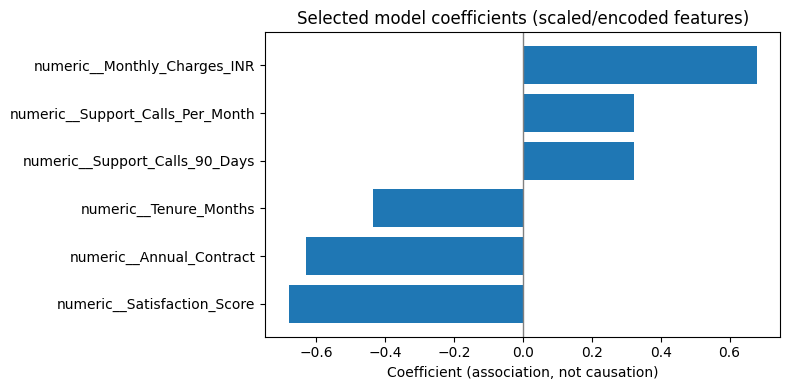

In [9]:
names=best.named_steps['preprocess'].get_feature_names_out()
selected=best.named_steps['select'].get_support()
selected_names=names[selected]
coefs=best.named_steps['model'].coef_[0]
importance=pd.DataFrame({'Feature':selected_names,'Logistic coefficient':coefs}).sort_values('Logistic coefficient')
display(importance)
importance.to_csv(OUTPUT/'selected_features.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));ax.barh(importance['Feature'],importance['Logistic coefficient']);ax.axvline(0,color='gray',linewidth=1);ax.set_title('Selected model coefficients (scaled/encoded features)');ax.set_xlabel('Coefficient (association, not causation)');fig.tight_layout();fig.savefig(OUTPUT/'selected_feature_coefficients.png',dpi=150);plt.show()

## 10. Save reusable pipeline and final checks
The saved pipeline contains imputation, scaling, one-hot encoding, feature selection, and the trained model. When predicting new rows, apply `create_features` first and then call `predict` or `predict_proba`. Do not use `Churn` or `Customer_ID` as predictors.

In [10]:
dump(best,OUTPUT/'day19_churn_pipeline.joblib')
assert len(X_train)+len(X_test)==len(df)
assert not X_train.index.intersection(X_test.index).size
assert not pd.isna(proba).any()
assert set(np.unique(pred)).issubset({0,1})
print('Saved pipeline and outputs to:',OUTPUT.resolve())
print('Final holdout ROC-AUC:',round(metrics['ROC-AUC'],4))
print('All sanity checks passed.')

Saved pipeline and outputs to: /mnt/data/Day19_Feature_Engineering/outputs
Final holdout ROC-AUC: 0.6921
All sanity checks passed.


## Conclusion
The assignment implements the institute workflow: raw data → cleaning → feature engineering → encoding → scaling → train/test → model. It additionally demonstrates cross-validation and hyperparameter tuning. The test results describe performance on **synthetic educational data only**, and must not be treated as real-world business performance. For unbiased tuned-model CV estimates, use nested cross-validation in future work.